# Retrieval plots

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

# scores are already computed, we're just drawing them here
data = json.loads(Path('plot_data.json').read_text())
labels = {'mrr_10': 'MRR@10', 'recall_100': 'Recall@100',
          'ndcg_10': 'NDCG@10', 'ndcg_100': 'NDCG@100', 'map': 'MAP'}

# keep the three judged sets together for each metric
groups = [
    ('MRR@10', {name: ['mrr_10'] for name in data}),
    ('Recall@100', {name: ['recall_100'] for name in data}),
    ('MAP / NDCG', {name: ['map'] if 'map' in block['metrics'] else ['ndcg_10', 'ndcg_100']
                    for name, block in data.items()}),
]

# names in the saved data are short; spell out what was actually run
systems = {
    'BM25': 'BM25 OR (top 100)',
    'Dense HNSW': 'HNSW (M=8, efC=200, efS=100; top 100)',
    'BM25 + dense (K=100)': 'BM25 OR + exact dense (K=100)',
}

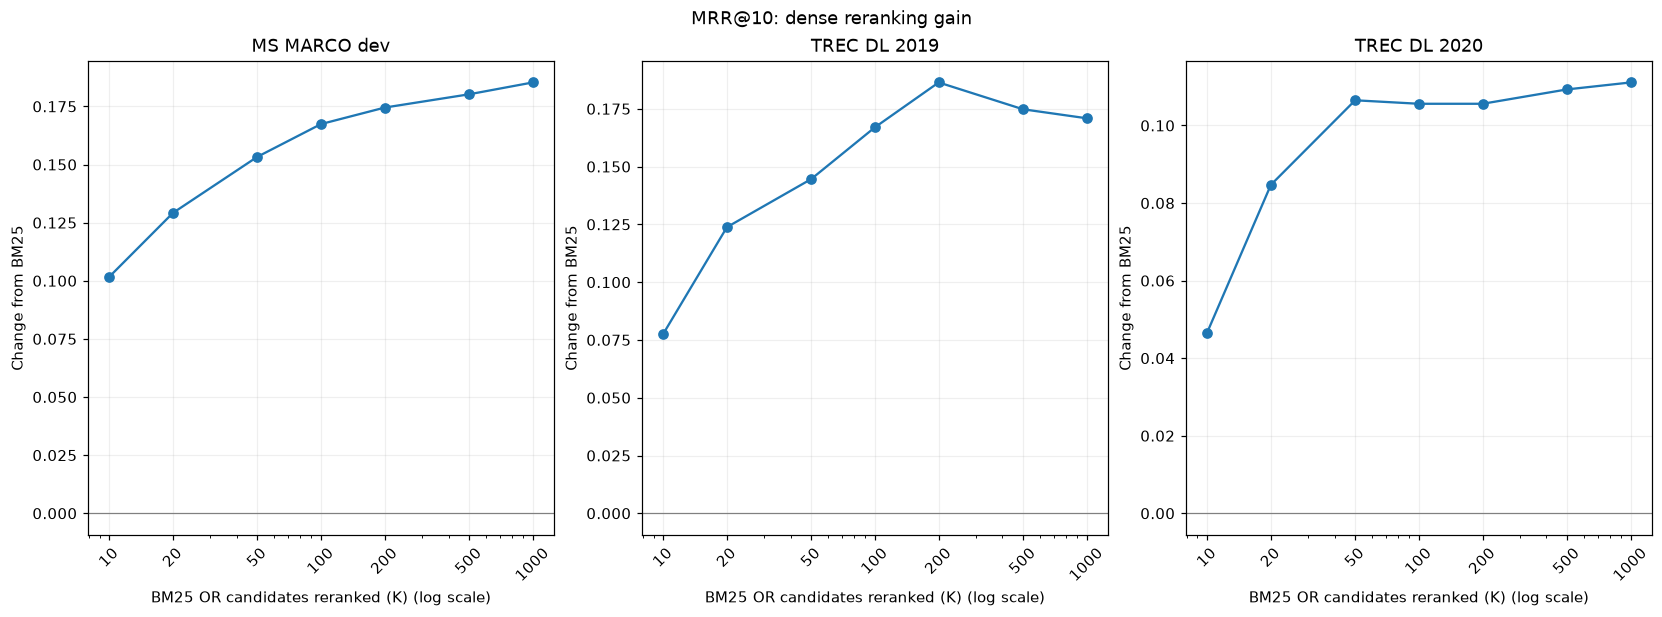

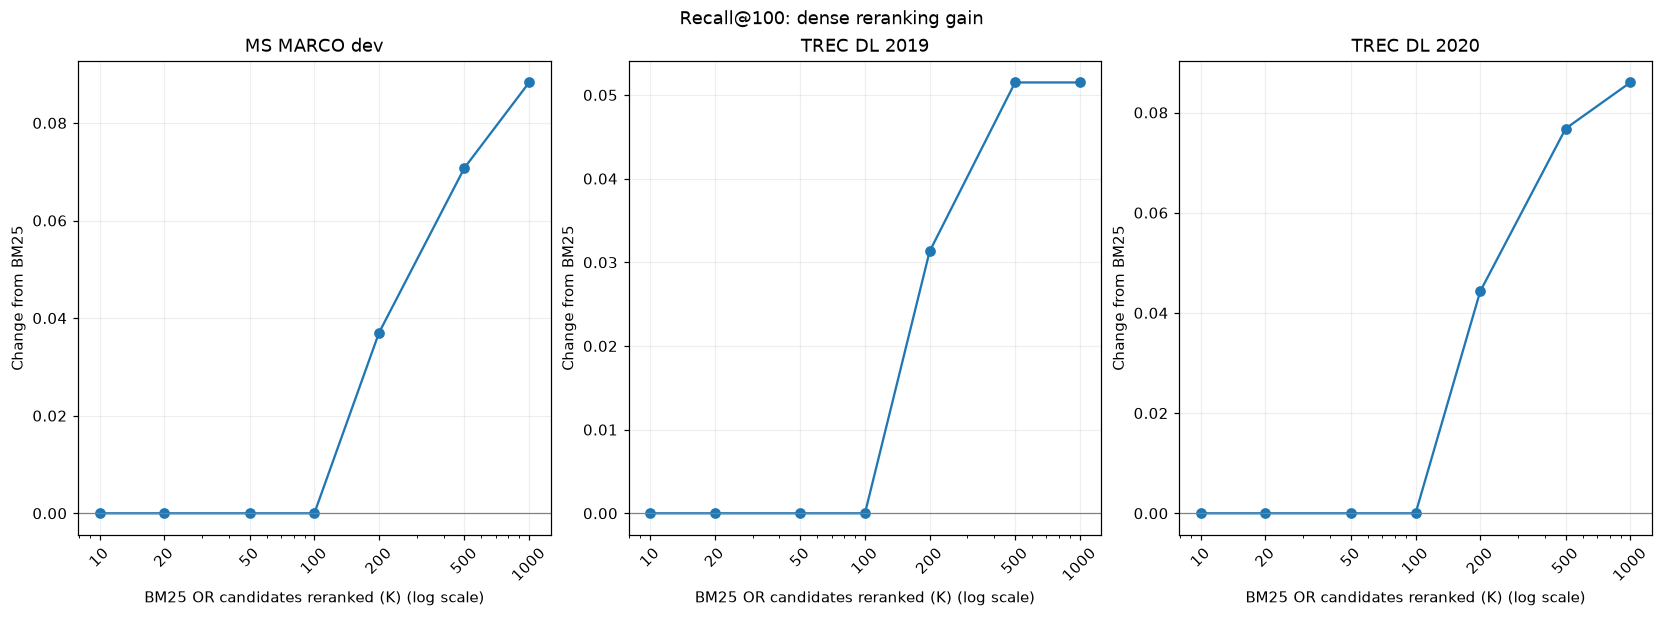

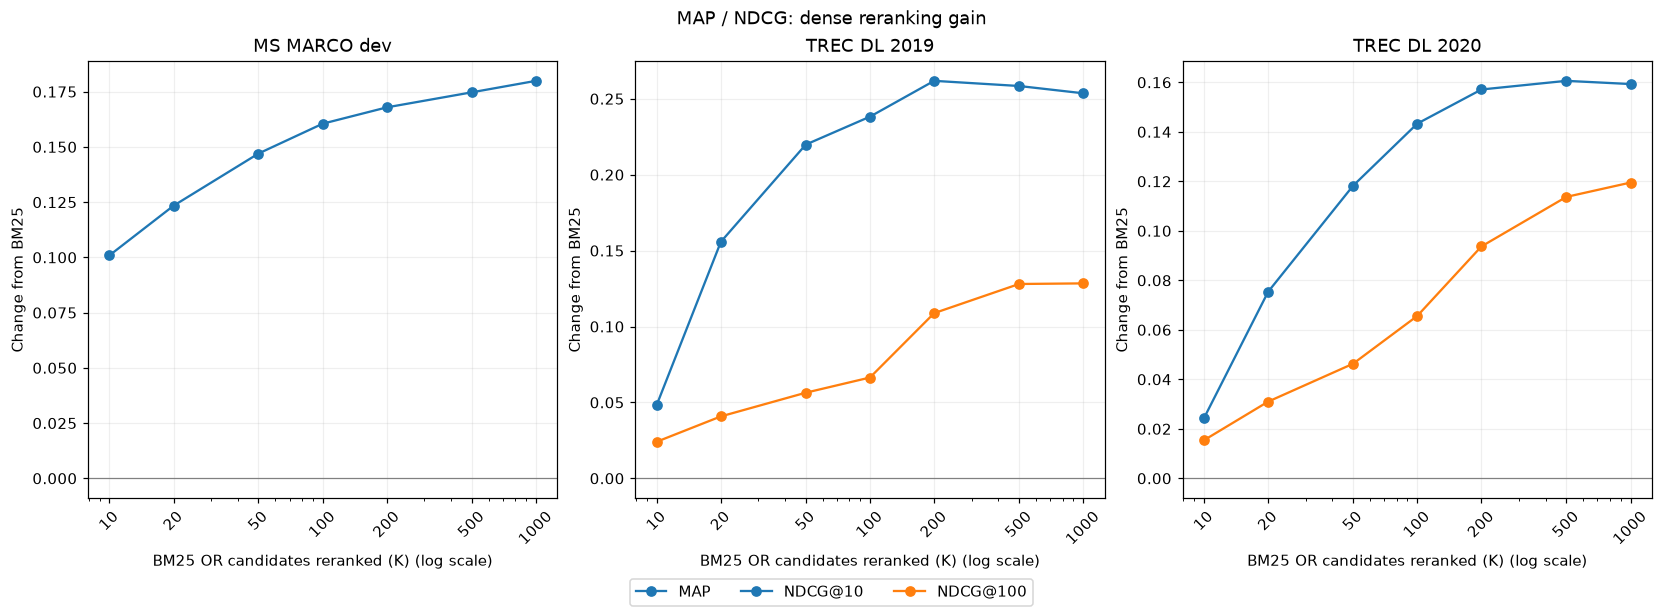

In [2]:
# one figure per metric group, with one panel for each judged set
for title, metrics_by_set in groups:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), layout='constrained')
    for ax, (dataset, block) in zip(axes, data.items()):
        ks = [int(k) for k in block['k']]
        for metric in metrics_by_set[dataset]:
            ax.plot(ks, [block['k'][str(k)][metric] for k in ks], marker='o', label=labels[metric])
        ax.axhline(0, color='gray', linewidth=0.8)
        ax.set_title(dataset)
        # spread out 10/20/50 so they don't get squished next to 1000
        ax.set_xscale('log')
        ax.set_xticks(ks, [str(k) for k in ks], rotation=45)
        ax.set_xlabel('BM25 OR candidates reranked (K) (log scale)')
        ax.set_ylabel('Change from BM25')
        ax.grid(alpha=0.2)
    if title == 'MAP / NDCG':
        dev_handles, dev_labels = axes[0].get_legend_handles_labels()
        eval_handles, eval_labels = axes[-1].get_legend_handles_labels()
        fig.legend(dev_handles + eval_handles, dev_labels + eval_labels,
                   loc='outside lower center', ncol=3)
    fig.suptitle(f'{title}: dense reranking gain')
    plt.show()

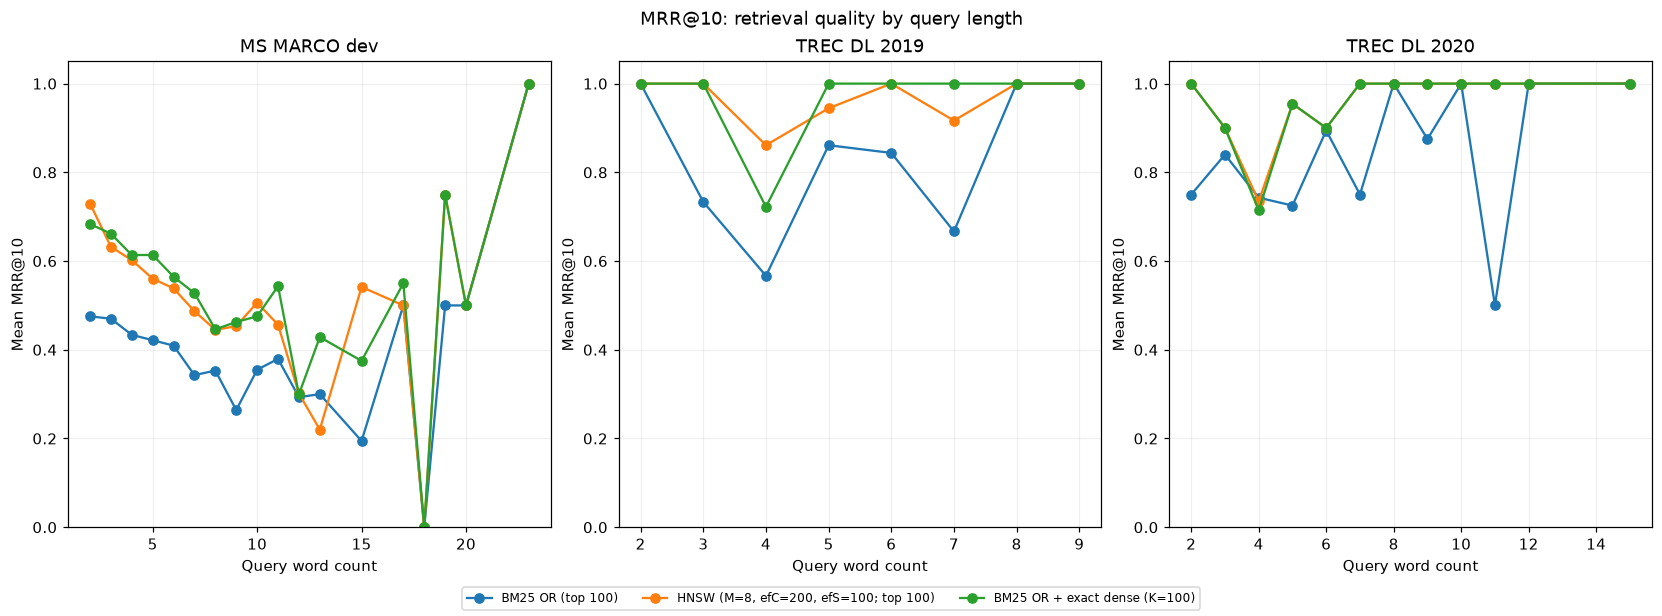

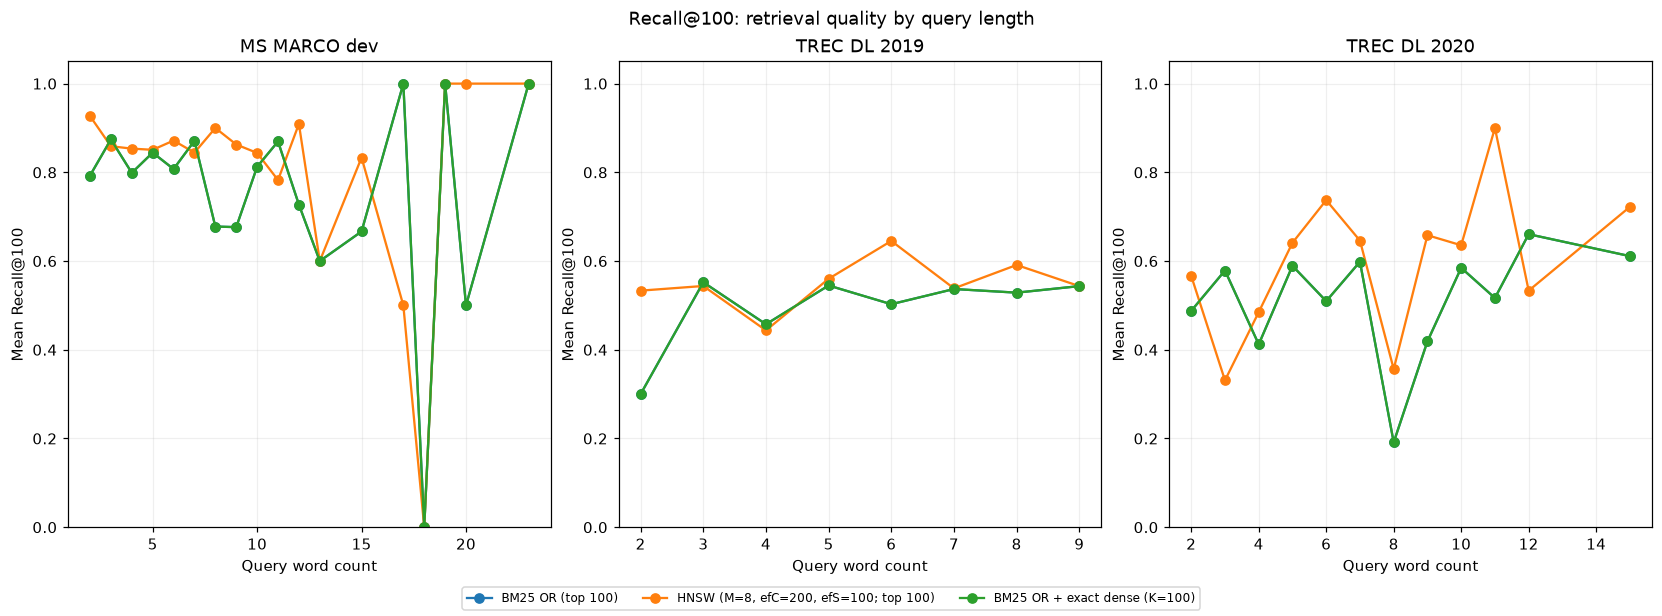

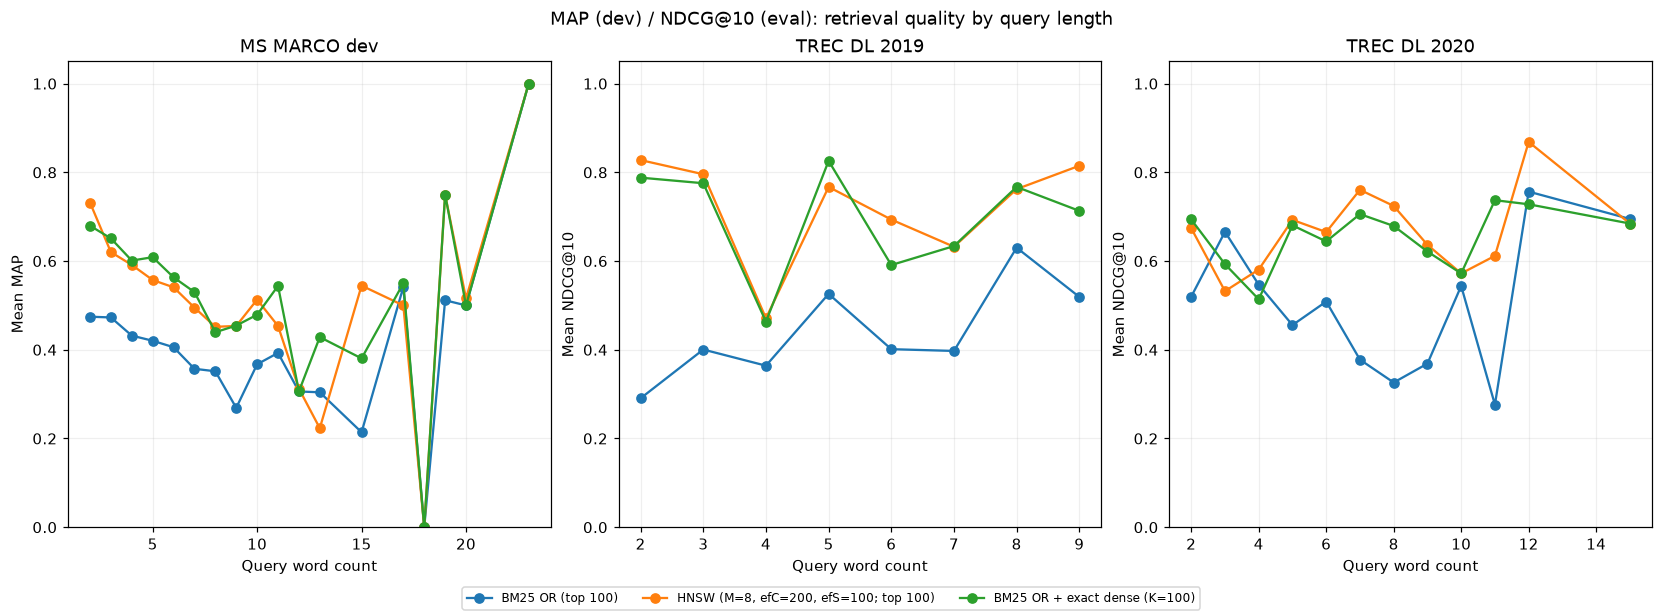

In [3]:
# each dot averages queries with exactly that many words
# the long-query tail gets jumpy when a length has only 1 or 2 queries
for title, metrics_by_set in groups:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), layout='constrained')
    for ax, (dataset, block) in zip(axes, data.items()):
        metric = metrics_by_set[dataset][0]  # MAP for dev, NDCG@10 for eval
        for system, scores in block['length'].items():
            lengths = sorted(map(int, scores))
            ax.plot(lengths, [scores[str(n)][metric] for n in lengths], marker='o', label=systems[system])
        ax.set_title(dataset)
        ax.set_xlabel('Query word count')
        ax.set_ylabel(f'Mean {labels[metric]}')
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.2)
    fig.legend(*axes[-1].get_legend_handles_labels(), loc='outside lower center', ncol=3, fontsize=8)
    fig.suptitle(f'{"MAP (dev) / NDCG@10 (eval)" if title == "MAP / NDCG" else title}: retrieval quality by query length')
    plt.show()